In [4]:
%pip install openpyxl

     -------------------------------------- 250.9/250.9 kB 1.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Đọc dữ liệu và tìm hiểu cấu trúc

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Đọc dữ liệu Excel
df = pd.read_excel("../1.2.3/data/onlineretail.xlsx")

# Nếu file của cậu là CSV, thay dòng trên bằng:
# df = pd.read_csv("Online Retail.csv", encoding="ISO-8859-1")

# Xem 5 dòng đầu
display(df.head())

# Kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Thông tin các cột
df.info()

# Thống kê mô tả
display(df.describe(include="all").T)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Số dòng: 541909
Số cột: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Kiểm tra chất lượng dữ liệu

In [6]:
# Số lượng giá trị thiếu
print("Giá trị thiếu theo cột:")
print(df.isnull().sum())

# Tỷ lệ thiếu theo phần trăm
print("\nTỷ lệ thiếu (%):")
print((df.isnull().mean() * 100).round(2))

# Số dòng trùng lặp
print("\nSố dòng trùng:", df.duplicated().sum())

# Kiểm tra số lượng âm hoặc bằng 0
print("\nQuantity <= 0:", (df["Quantity"] <= 0).sum())

# Kiểm tra giá bán âm hoặc bằng 0
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

# Kiểm tra hóa đơn hủy
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Số dòng có mã hóa đơn bắt đầu bằng C:", cancelled.sum())

Giá trị thiếu theo cột:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Tỷ lệ thiếu (%):
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

Số dòng trùng: 5268

Quantity <= 0: 10624
UnitPrice <= 0: 2517
Số dòng có mã hóa đơn bắt đầu bằng C: 9288


## 3. Làm sạch và tạo biến doanh thu

In [7]:
df_clean = df.copy()

# Chuyển InvoiceDate sang kiểu ngày giờ
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

# Chuẩn hóa dữ liệu văn bản
df_clean["Description"] = df_clean["Description"].astype("string").str.strip()
df_clean["Country"] = df_clean["Country"].astype("string").str.strip()

# Tạo cột doanh thu ở cấp dòng giao dịch
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Kiểm tra dữ liệu sau khi xử lý
display(df_clean.head())
print("Kích thước dữ liệu:", df_clean.shape)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


Kích thước dữ liệu: (541909, 9)


In [8]:
valid_sales = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
    & (df_clean["InvoiceDate"].notna())
].copy()

print("Số dòng dùng để phân tích doanh thu:", len(valid_sales))
print("Tổng doanh thu:", round(valid_sales["Revenue"].sum(), 2))

Số dòng dùng để phân tích doanh thu: 530104
Tổng doanh thu: 10666684.54


## 4. Trực quan hóa dữ liệu

#### 4.1. Phân bố số lượng và đơn giá sản phẩm

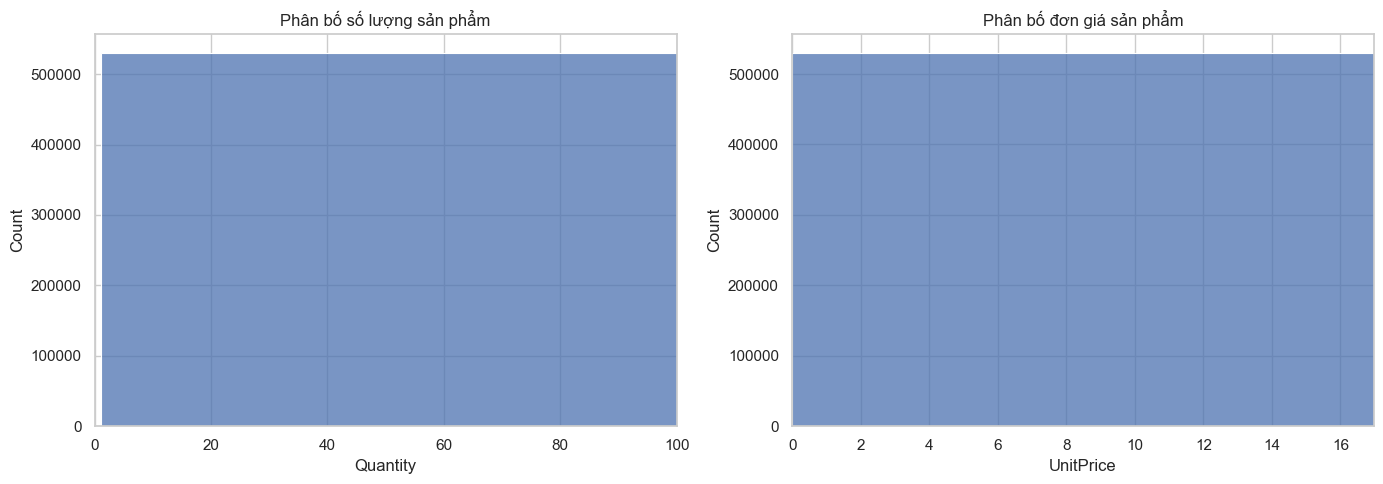

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=valid_sales, x="Quantity",
    bins=40, ax=axes[0]
)
axes[0].set_xlim(0, valid_sales["Quantity"].quantile(0.99))
axes[0].set_title("Phân bố số lượng sản phẩm")

sns.histplot(
    data=valid_sales, x="UnitPrice",
    bins=40, ax=axes[1]
)
axes[1].set_xlim(0, valid_sales["UnitPrice"].quantile(0.99))
axes[1].set_title("Phân bố đơn giá sản phẩm")

plt.tight_layout()
plt.show()

#### 4.2. Top 10 sản phẩm bán chạy theo số lượng

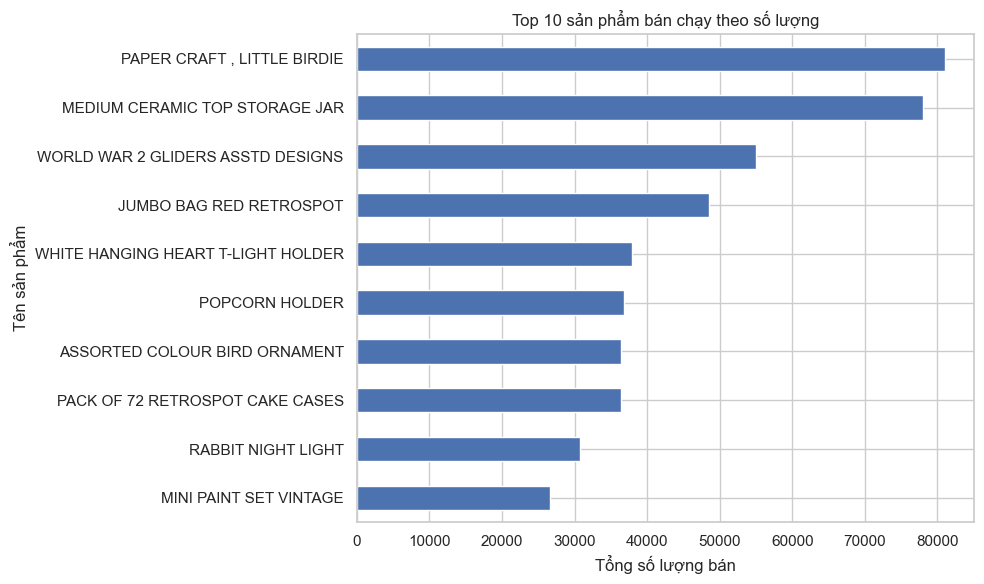

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [10]:
top_products = (
    valid_sales.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_products.plot(kind="barh")

plt.title("Top 10 sản phẩm bán chạy theo số lượng")
plt.xlabel("Tổng số lượng bán")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()

display(top_products.sort_values(ascending=False))

#### 4.3. Top 10 sản phẩm theo doanh thu

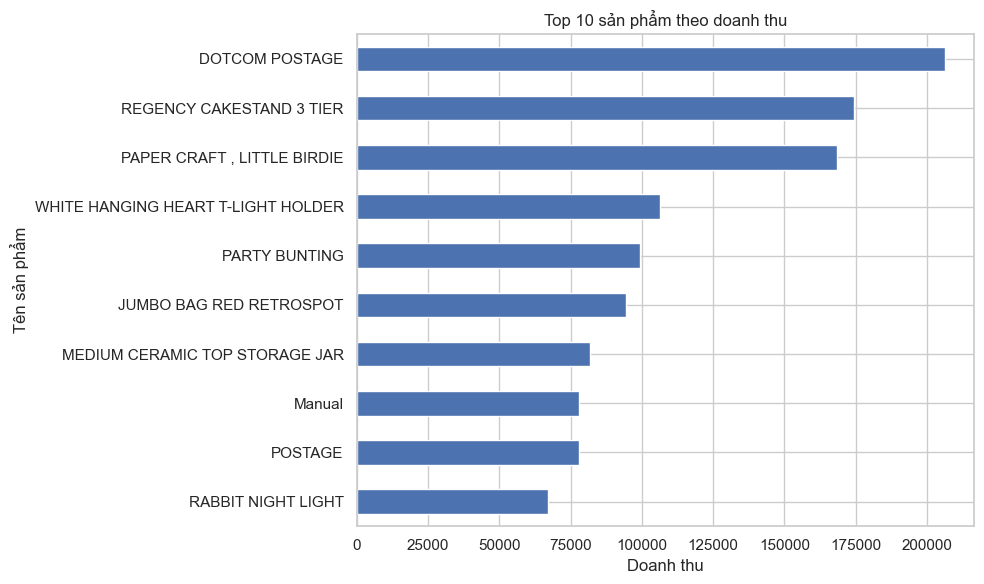

In [11]:
top_revenue_products = (
    valid_sales.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_revenue_products.plot(kind="barh")

plt.title("Top 10 sản phẩm theo doanh thu")
plt.xlabel("Doanh thu")
plt.ylabel("Tên sản phẩm")
plt.tight_layout()
plt.show()

#### 4.4. Doanh thu theo quốc gia

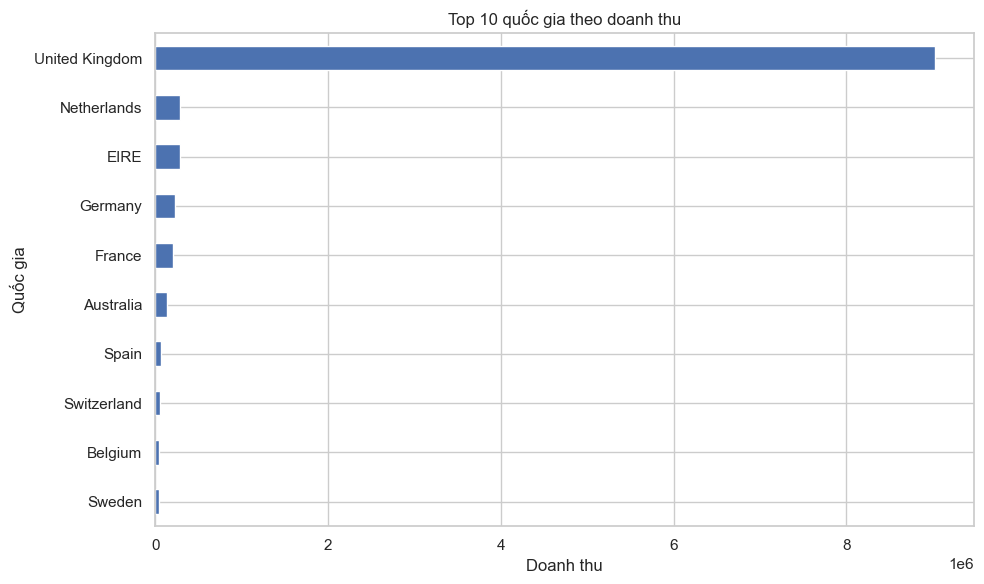

In [12]:
country_revenue = (
    valid_sales.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
country_revenue.plot(kind="barh")

plt.title("Top 10 quốc gia theo doanh thu")
plt.xlabel("Doanh thu")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

#### 4.5. Xu hướng doanh thu theo tháng

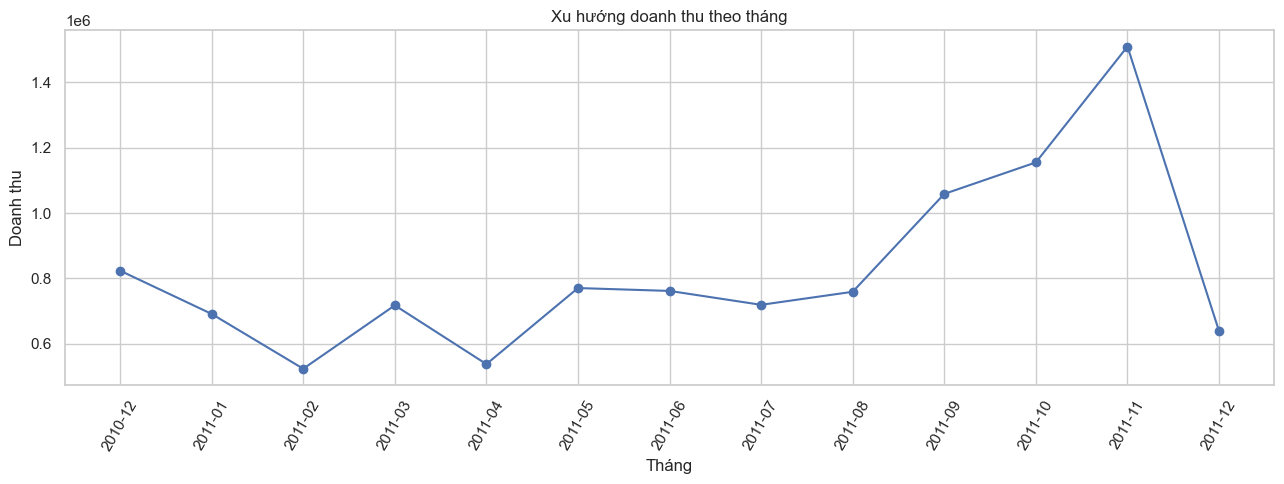

In [13]:
valid_sales["YearMonth"] = (
    valid_sales["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_revenue = (
    valid_sales.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(13, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")

plt.title("Xu hướng doanh thu theo tháng")
plt.xlabel("Tháng")
plt.ylabel("Doanh thu")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

#### 4.6. Số lượng đơn hàng theo giờ

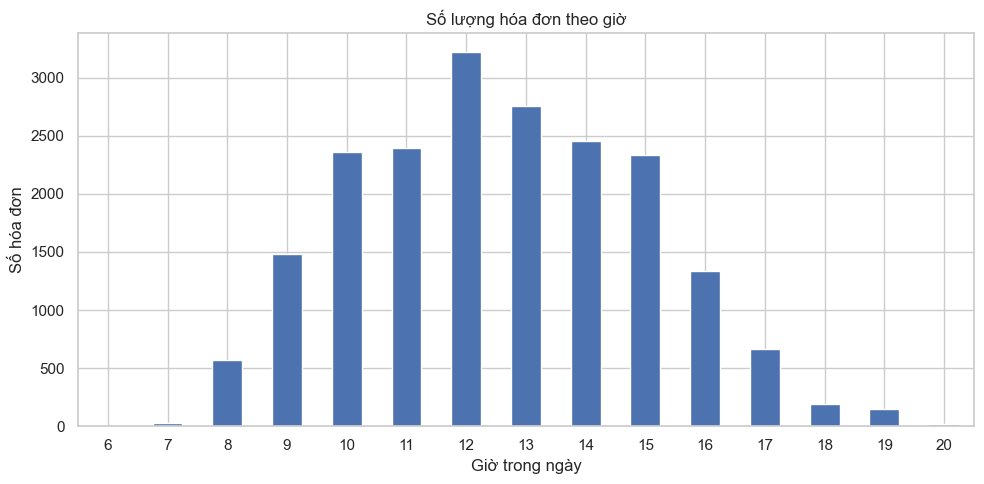

In [14]:
valid_sales["Hour"] = valid_sales["InvoiceDate"].dt.hour

orders_by_hour = (
    valid_sales.groupby("Hour")["InvoiceNo"]
    .nunique()
)

plt.figure(figsize=(10, 5))
orders_by_hour.plot(kind="bar")

plt.title("Số lượng hóa đơn theo giờ")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Số hóa đơn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 4.7. Phân tích khách hàng

,Total_Spent,Total_Orders,Total_Quantity
count,4338.000000,4338.000000,4338.000000
mean,2054.266460,4.272015,1191.289073
std,8989.230441,7.697998,5046.081546
min,3.750000,1.000000,1.000000
25%,307.415000,1.000000,160.000000
50%,674.485000,2.000000,379.000000
75%,1661.740000,5.000000,992.750000
max,280206.020000,209.000000,196915.000000


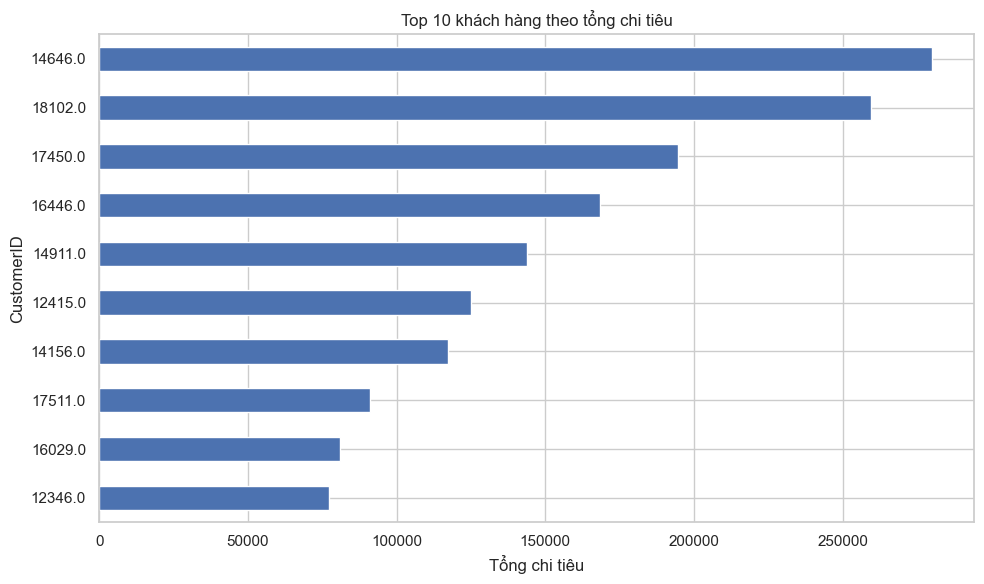

In [15]:
customer_sales = valid_sales.dropna(subset=["CustomerID"]).copy()

# Tổng chi tiêu và số hóa đơn theo khách hàng
customer_summary = customer_sales.groupby("CustomerID").agg(
    Total_Spent=("Revenue", "sum"),
    Total_Orders=("InvoiceNo", "nunique"),
    Total_Quantity=("Quantity", "sum")
)

display(customer_summary.describe())

# Top 10 khách hàng theo tổng chi tiêu
top_customers = (
    customer_summary["Total_Spent"]
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
top_customers.plot(kind="barh")

plt.title("Top 10 khách hàng theo tổng chi tiêu")
plt.xlabel("Tổng chi tiêu")
plt.ylabel("CustomerID")
plt.tight_layout()
plt.show()

## 5. Tổng hợp các chỉ số chính

In [16]:
summary = {
    "Số dòng dữ liệu gốc": len(df_clean),
    "Số hóa đơn hợp lệ": valid_sales["InvoiceNo"].nunique(),
    "Số khách hàng xác định": valid_sales["CustomerID"].nunique(),
    "Số sản phẩm khác nhau": valid_sales["StockCode"].nunique(),
    "Số quốc gia": valid_sales["Country"].nunique(),
    "Tổng số lượng bán": valid_sales["Quantity"].sum(),
    "Tổng doanh thu": valid_sales["Revenue"].sum(),
    "Giá trị trung bình mỗi dòng": valid_sales["Revenue"].mean()
}

display(pd.Series(summary, name="Giá trị").to_frame())

,Giá trị
Số dòng dữ liệu gốc,5.419090e+05
Số hóa đơn hợp lệ,1.996000e+04
Số khách hàng xác định,4.338000e+03
Số sản phẩm khác nhau,3.922000e+03
Số quốc gia,3.800000e+01
Tổng số lượng bán,5.588376e+06
Tổng doanh thu,1.066668e+07
Giá trị trung bình mỗi dòng,2.012187e+01


In [17]:
invoice_revenue = valid_sales.groupby("InvoiceNo")["Revenue"].sum()

print("Doanh thu trung bình mỗi hóa đơn:",
      round(invoice_revenue.mean(), 2))

Doanh thu trung bình mỗi hóa đơn: 534.4
